**Cell 1 — Setup, LOL download, inspect ExDark**

In [1]:
# Cell 1 — Setup, LOL download, inspect official ExDark repo
!nvidia-smi --query-gpu=name,memory.total --format=csv

from google.colab import drive
drive.mount('/content/drive')

!pip install -q pycocotools torchmetrics scikit-image

import os, glob, zipfile, platform
import numpy as np, cv2, torch, skimage

PROJECT_DIR = '/content/drive/MyDrive/IPCVai_LowLight'
for sub in ['data', 'checkpoints', 'results', 'figures']:
    os.makedirs(f'{PROJECT_DIR}/{sub}', exist_ok=True)

name, memory.total [MiB]
Tesla T4, 15360 MiB
Mounted at /content/drive


In [2]:
# ---------- LOL (Hugging Face mirror of the BMVC 2018 release) ----------
LOL_ZIP = f'{PROJECT_DIR}/data/lol_dataset.zip'
if not os.path.exists(LOL_ZIP):
    !wget -q -O {LOL_ZIP} https://huggingface.co/datasets/geekyrakshit/LoL-Dataset/resolve/main/lol_dataset.zip
print(f'LOL zip: {os.path.getsize(LOL_ZIP)/1e6:.1f} MB')
with zipfile.ZipFile(LOL_ZIP) as z:
    z.extractall('/content/lol')

print('\nLOL folders with images:')
for d in sorted({os.path.dirname(p) for p in glob.glob('/content/lol/**/*.png', recursive=True)}):
    print(f'  {d:<55} {len(glob.glob(d + "/*.png")):>4} images')

# ---------- ExDark: official repo (skip large LFS files for now) ----------
!GIT_LFS_SKIP_SMUDGE=1 git clone -q --depth 1 https://github.com/cs-chan/Exclusively-Dark-Image-Dataset.git /content/exdark_repo
print('\nExDark repo structure (depth 2):')
!find /content/exdark_repo -maxdepth 2 -not -path '*/.git*' | sort | head -60
print('\nRepo size:')
!du -sh /content/exdark_repo --exclude=.git
print('\nText/README files in Dataset/ and Groundtruth/:')
for p in sorted(glob.glob('/content/exdark_repo/Dataset/*') + glob.glob('/content/exdark_repo/Groundtruth/*')):
    if p.lower().endswith(('.md', '.txt')) and os.path.getsize(p) < 20000:
        print(f'\n===== {p} =====')
        print(open(p, errors='ignore').read()[:1500])

print(f'\nPython {platform.python_version()} | torch {torch.__version__} | CUDA {torch.cuda.is_available()} '
      f'| OpenCV {cv2.__version__} | scikit-image {skimage.__version__} | CPU cores {os.cpu_count()}')

LOL zip: 347.2 MB

LOL folders with images:
  /content/lol/lol_dataset/eval15/high                      15 images
  /content/lol/lol_dataset/eval15/low                       15 images
  /content/lol/lol_dataset/our485/high                     485 images
  /content/lol/lol_dataset/our485/low                      485 images

ExDark repo structure (depth 2):
/content/exdark_repo
/content/exdark_repo/Dataset
/content/exdark_repo/Dataset/DATASET_TERMS.md
/content/exdark_repo/Dataset/exdarkimg.gif
/content/exdark_repo/Dataset/README.md
/content/exdark_repo/Dataset/RIGHTS_NOTICE.md
/content/exdark_repo/Dataset/Thumbnails.png
/content/exdark_repo/Exdark.gif
/content/exdark_repo/Groundtruth
/content/exdark_repo/Groundtruth/annotations.png
/content/exdark_repo/Groundtruth/exdark1.png
/content/exdark_repo/Groundtruth/imageclasslist.txt
/content/exdark_repo/Groundtruth/README.md
/content/exdark_repo/LICENSE
/content/exdark_repo/README.md
/content/exdark_repo/SPIC
/content/exdark_repo/SPIC/2015_000

**Cell 2 — Download ExDark and check its structure**

In [3]:
# Cell 2 — Download ExDark (images + ground truth) and inspect structure, annotations, splits
import gdown
from collections import Counter

EX_IMG_ZIP = f'{PROJECT_DIR}/data/ExDark_images.zip'
EX_GT_ZIP  = f'{PROJECT_DIR}/data/ExDark_groundtruth.zip'
if not os.path.exists(EX_IMG_ZIP):
    gdown.download(id='1BHmPgu8EsHoFDDkMGLVoXIlCth2dW6Yx', output=EX_IMG_ZIP, quiet=False)
if not os.path.exists(EX_GT_ZIP):
    gdown.download(id='1P3iO3UYn7KoBi5jiUkogJq96N6maZS1i', output=EX_GT_ZIP, quiet=False)

for zp, dst in [(EX_IMG_ZIP, '/content/exdark/images'), (EX_GT_ZIP, '/content/exdark/gt')]:
    print(f'{os.path.basename(zp)}: {os.path.getsize(zp)/1e6:.1f} MB | zip: {zipfile.is_zipfile(zp)}')
    if zipfile.is_zipfile(zp):
        with zipfile.ZipFile(zp) as z:
            z.extractall(dst)
    else:
        !file {zp}

print('\nFolders (depth 3):')
!find /content/exdark -maxdepth 3 -type d | sort | head -40

imgs = [p for p in glob.glob('/content/exdark/images/**/*', recursive=True) if os.path.isfile(p)]
anns = [p for p in glob.glob('/content/exdark/gt/**/*', recursive=True) if os.path.isfile(p)]
print(f'\nImage files: {len(imgs)} | extensions: {dict(Counter(os.path.splitext(p)[1] for p in imgs))}')
print(f'Annotation files: {len(anns)} | extensions: {dict(Counter(os.path.splitext(p)[1] for p in anns))}')
print('Example image names:', [os.path.basename(p) for p in imgs[:3]])
print('Example annotation names:', [os.path.basename(p) for p in anns[:3]])

print(f'\n----- Example annotation: {anns[0]} -----')
print(open(anns[0], errors='ignore').read()[:400])

lines = open('/content/exdark_repo/Groundtruth/imageclasslist.txt').read().splitlines()
print(f'\nimageclasslist.txt: {len(lines)} lines | first 4:')
for l in lines[:4]:
    print('   ', l)
rows = [l.split() for l in lines[1:] if l.strip()]
ncol = Counter(len(r) for r in rows)
print('Columns per row:', dict(ncol))
for c in range(1, max(ncol) ):
    vals = Counter(r[c] for r in rows if len(r) > c)
    if len(vals) <= 12:
        print(f'  column {c+1} values: {dict(sorted(vals.items()))}')

ExDark_images.zip: 1492.1 MB | zip: True
ExDark_groundtruth.zip: 5.1 MB | zip: True

Folders (depth 3):
/content/exdark
/content/exdark/gt
/content/exdark/gt/ExDark_Annno
/content/exdark/gt/ExDark_Annno/Bicycle
/content/exdark/gt/ExDark_Annno/Boat
/content/exdark/gt/ExDark_Annno/Bottle
/content/exdark/gt/ExDark_Annno/Bus
/content/exdark/gt/ExDark_Annno/Car
/content/exdark/gt/ExDark_Annno/Cat
/content/exdark/gt/ExDark_Annno/Chair
/content/exdark/gt/ExDark_Annno/Cup
/content/exdark/gt/ExDark_Annno/Dog
/content/exdark/gt/ExDark_Annno/Motorbike
/content/exdark/gt/ExDark_Annno/People
/content/exdark/gt/ExDark_Annno/Table
/content/exdark/gt/__MACOSX
/content/exdark/gt/__MACOSX/ExDark_Annno
/content/exdark/images
/content/exdark/images/ExDark
/content/exdark/images/ExDark/Bicycle
/content/exdark/images/ExDark/Boat
/content/exdark/images/ExDark/Bottle
/content/exdark/images/ExDark/Bus
/content/exdark/images/ExDark/Car
/content/exdark/images/ExDark/Cat
/content/exdark/images/ExDark/Chair
/conte

**Cell 3 — Build the ExDark index (images ↔ boxes ↔ split ↔ lighting)**

In [ ]:
# Cell 3 — Build ExDark index: images <-> annotations <-> official split, COCO class mapping
import json
from PIL import Image

EX_IMG_ROOT = '/content/exdark/images/ExDark'
EX_GT_ROOT  = '/content/exdark/gt/ExDark_Annno'
CLASSES = ['Bicycle', 'Boat', 'Bottle', 'Bus', 'Car', 'Cat', 'Chair', 'Cup', 'Dog', 'Motorbike', 'People', 'Table']
TO_COCO = {'Bicycle': 'bicycle', 'Boat': 'boat', 'Bottle': 'bottle', 'Bus': 'bus', 'Car': 'car', 'Cat': 'cat',
           'Chair': 'chair', 'Cup': 'cup', 'Dog': 'dog', 'Motorbike': 'motorcycle', 'People': 'person',
           'Table': 'dining table'}
SPLIT = {'1': 'train', '2': 'val', '3': 'test'}
LIGHT = {1: 'Low', 2: 'Ambient', 3: 'Object', 4: 'Single', 5: 'Weak', 6: 'Strong',
         7: 'Screen', 8: 'Window', 9: 'Shadow', 10: 'Twilight'}

img_by_name = {os.path.basename(p).lower(): p for p in glob.glob(f'{EX_IMG_ROOT}/*/*') if os.path.isfile(p)}
ann_by_name = {os.path.basename(p)[:-4].lower(): p for p in glob.glob(f'{EX_GT_ROOT}/*/*.txt')}

index, miss_img, miss_ann, unknown, out_of_bounds = [], 0, 0, Counter(), 0
for line in lines[1:]:
    name, cls, light, inout, split = line.split()
    ip, ap = img_by_name.get(name.lower()), ann_by_name.get(name.lower())
    if ip is None:
        miss_img += 1; continue
    if ap is None:
        miss_ann += 1; continue
    with Image.open(ip) as im:                      # reads header only -> fast
        W, H = im.size
    boxes = []
    for row in open(ap, errors='ignore').read().splitlines()[1:]:
        t = row.split()
        if len(t) < 5:
            continue
        if t[0] not in TO_COCO:
            unknown[t[0]] += 1; continue
        x, y, w, h = map(float, t[1:5])
        if x < 0 or y < 0 or x + w > W + 1 or y + h > H + 1 or w <= 0 or h <= 0:
            out_of_bounds += 1
        boxes.append([t[0], x, y, w, h])
    index.append(dict(name=name, path=ip, cls=CLASSES[int(cls) - 1], light=LIGHT[int(light)],
                      inout=int(inout), split=SPLIT[split], width=W, height=H, boxes=boxes))

print(f'Indexed: {len(index)} | missing image: {miss_img} | missing annotation: {miss_ann}')
print(f'Unknown box labels: {dict(unknown)} | boxes outside image: {out_of_bounds}')
for s in ['train', 'val', 'test']:
    sub = [r for r in index if r['split'] == s]
    print(f'{s:<5}: {len(sub):>5} images | {sum(len(r["boxes"]) for r in sub):>6} boxes')

test = [r for r in index if r['split'] == 'test']
print('\nTest boxes per class:', dict(Counter(b[0] for r in test for b in r['boxes']).most_common()))
print('Test images per lighting type:', dict(Counter(r['light'] for r in test).most_common()))
ws, hs = [r['width'] for r in index], [r['height'] for r in index]
print(f'Image width min/median/max: {min(ws)} / {int(np.median(ws))} / {max(ws)} | '
      f'height: {min(hs)} / {int(np.median(hs))} / {max(hs)}')

with open(f'{PROJECT_DIR}/data/exdark_index.json', 'w') as f:
    json.dump(dict(classes=CLASSES, to_coco=TO_COCO, index=index), f)
print(f'\nSaved {PROJECT_DIR}/data/exdark_index.json')

Indexed: 7363 | missing image: 0 | missing annotation: 0
Unknown box labels: {} | boxes outside image: 17
train:  3000 images |  10381 boxes
val  :  1800 images |   6212 boxes
test :  2563 images |   7117 boxes

Test boxes per class: {'People': 2235, 'Car': 919, 'Chair': 609, 'Boat': 515, 'Dog': 490, 'Bottle': 433, 'Cat': 425, 'Bicycle': 418, 'Cup': 356, 'Table': 311, 'Motorbike': 242, 'Bus': 164}
Test images per lighting type: {'Ambient': 925, 'Strong': 538, 'Single': 255, 'Weak': 232, 'Twilight': 174, 'Object': 144, 'Low': 134, 'Window': 119, 'Screen': 28, 'Shadow': 14}
Image width min/median/max: 144 / 640 / 4372 | height: 150 / 500 / 4160

Saved /content/drive/MyDrive/IPCVai_LowLight/data/exdark_index.json


## **Phase 2 — Classical methods on LOL**

**Cell 4 — Classical enhancement methods: quality and speed**

In [ ]:
# Cell 4 — Classical enhancement methods + image quality on LOL (PSNR / SSIM / time)
import time
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim

def m_none(img):
    return img

def m_gamma(img):
    """Adaptive gamma: maps the image's mean luminance to 0.5."""
    y = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).mean() / 255
    g = np.log(0.5) / np.log(np.clip(y, 1e-3, 0.99))
    lut = (np.linspace(0, 1, 256) ** g * 255).clip(0, 255).astype(np.uint8)
    return cv2.LUT(img, lut)

def m_he(img):
    ycc = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)
    ycc[..., 0] = cv2.equalizeHist(ycc[..., 0])
    return cv2.cvtColor(ycc, cv2.COLOR_YCrCb2RGB)

_clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
def m_clahe(img):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    lab[..., 0] = _clahe.apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def _big_blur(img, sigma):
    """Gaussian blur; large sigmas computed at 1/4 scale (smooth result, much faster)."""
    if sigma < 30:
        return cv2.GaussianBlur(img, (0, 0), sigma)
    h, w = img.shape[:2]
    small = cv2.resize(img, (max(1, w // 4), max(1, h // 4)), interpolation=cv2.INTER_AREA)
    small = cv2.GaussianBlur(small, (0, 0), sigma / 4)
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)

def m_msrcr(img, sigmas=(15, 80, 250), alpha=125.0, beta=46.0, G=5.0, b=25.0):
    """Multi-Scale Retinex with Colour Restoration (Jobson et al., 1997) + percentile stretch."""
    x = img.astype(np.float32) + 1.0
    retinex = sum(np.log10(x) - np.log10(_big_blur(x, s)) for s in sigmas) / len(sigmas)
    crf = beta * (np.log10(alpha * x) - np.log10(x.sum(axis=2, keepdims=True)))
    out = G * (retinex * crf + b)
    for c in range(3):
        lo, hi = np.percentile(out[..., c], (1, 99))
        out[..., c] = (out[..., c] - lo) / max(hi - lo, 1e-6) * 255
    return out.clip(0, 255).astype(np.uint8)

def m_gamma_nlm(img):
    return cv2.fastNlMeansDenoisingColored(m_gamma(img), None, h=7, hColor=7,
                                           templateWindowSize=7, searchWindowSize=21)

CLASSICAL = {'None': m_none, 'Gamma': m_gamma, 'HE': m_he, 'CLAHE': m_clahe,
             'MSRCR': m_msrcr, 'Gamma+NLM': m_gamma_nlm}

# ---------- Load all 500 LOL pairs ----------
def read_rgb(p):
    return cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)

lol = []
for sub in ['our485', 'eval15']:
    for lp in sorted(glob.glob(f'/content/lol/lol_dataset/{sub}/low/*.png')):
        lol.append((sub, os.path.basename(lp), read_rgb(lp), read_rgb(lp.replace('/low/', '/high/'))))
print(f'LOL pairs loaded: {len(lol)} ({sum(s == "eval15" for s, *_ in lol)} official test)')

# ---------- Evaluate ----------
lol_res = {}
for mname, fn in CLASSICAL.items():
    ps, ss, ts = [], [], []
    for sub, n, low, high in lol:
        t0 = time.perf_counter()
        out = fn(low)
        ts.append((time.perf_counter() - t0) * 1000)
        ps.append(psnr(high, out, data_range=255))
        ss.append(ssim(high, out, channel_axis=-1, data_range=255))
    lol_res[mname] = dict(psnr=ps, ssim=ss, ms=ts)
    print(f'done: {mname}')

is_test = np.array([s == 'eval15' for s, *_ in lol])
print(f"\n{'method':<11}{'PSNR all':>10}{'SSIM all':>10}{'PSNR test15':>13}{'SSIM test15':>13}{'ms/img':>9}")
for m, r in lol_res.items():
    p, s = np.array(r['psnr']), np.array(r['ssim'])
    print(f"{m:<11}{p.mean():>10.2f}{s.mean():>10.3f}{p[is_test].mean():>13.2f}{s[is_test].mean():>13.3f}"
          f"{np.median(r['ms']):>9.1f}")

with open(f'{PROJECT_DIR}/results/lol_classical.json', 'w') as f:
    json.dump(dict(names=[n for _, n, *_ in lol], subset=[s for s, *_ in lol], results=lol_res), f)

# ---------- Example figure: 3 official test images ----------
picks = [i for i, (s, *_) in enumerate(lol) if s == 'eval15'][:3]
cols = ['Low (input)'] + list(CLASSICAL)[1:] + ['Reference']
fig, axes = plt.subplots(len(picks), len(cols), figsize=(3.2 * len(cols), 2.4 * len(picks)))
for r, i in enumerate(picks):
    _, n, low, high = lol[i]
    outs = [low] + [CLASSICAL[m](low) for m in list(CLASSICAL)[1:]] + [high]
    for c, (img, title) in enumerate(zip(outs, cols)):
        axes[r, c].imshow(img); axes[r, c].axis('off')
        if r == 0:
            axes[r, c].set_title(title, fontsize=11)
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/figures/lol_classical_examples.png', dpi=100)
plt.show()

### **Phase 3 — Zero-DCE (deep learning)**

**Cell 5 — Train Zero-DCE on ExDark train images, evaluate on LOL**

In [ ]:
# Cell 5 — Zero-DCE: train on ExDark train split (zero-reference), evaluate on all 500 LOL pairs
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

DEVICE = 'cuda'
torch.manual_seed(42); np.random.seed(42)

# ---------- DCE-Net (Guo et al., CVPR 2020) ----------
class DCENet(nn.Module):
    def __init__(self, nf=32):
        super().__init__()
        self.c1, self.c2 = nn.Conv2d(3, nf, 3, 1, 1), nn.Conv2d(nf, nf, 3, 1, 1)
        self.c3, self.c4 = nn.Conv2d(nf, nf, 3, 1, 1), nn.Conv2d(nf, nf, 3, 1, 1)
        self.c5, self.c6 = nn.Conv2d(2 * nf, nf, 3, 1, 1), nn.Conv2d(2 * nf, nf, 3, 1, 1)
        self.c7 = nn.Conv2d(2 * nf, 24, 3, 1, 1)

    def forward(self, x):
        x1 = F.relu(self.c1(x)); x2 = F.relu(self.c2(x1))
        x3 = F.relu(self.c3(x2)); x4 = F.relu(self.c4(x3))
        x5 = F.relu(self.c5(torch.cat([x3, x4], 1)))
        x6 = F.relu(self.c6(torch.cat([x2, x5], 1)))
        A = torch.tanh(self.c7(torch.cat([x1, x6], 1)))
        y = x
        for r in torch.split(A, 3, dim=1):               # 8 iterations of the light-enhancement curve
            y = y + r * (y * y - y)
        return y, A

# ---------- Zero-reference losses (official weights: spa 1, exp 10, col 5, tv 200) ----------
_k = {'l': [[0, 0, 0], [-1, 1, 0], [0, 0, 0]], 'r': [[0, 0, 0], [0, 1, -1], [0, 0, 0]],
      'u': [[0, -1, 0], [0, 1, 0], [0, 0, 0]], 'd': [[0, 0, 0], [0, 1, 0], [0, -1, 0]]}
KERNELS = [torch.tensor(v, dtype=torch.float32).view(1, 1, 3, 3).to(DEVICE) for v in _k.values()]

def loss_spa(org, enh):
    o = F.avg_pool2d(org.mean(1, keepdim=True), 4)
    e = F.avg_pool2d(enh.mean(1, keepdim=True), 4)
    return sum(((F.conv2d(o, k, padding=1) - F.conv2d(e, k, padding=1)) ** 2) for k in KERNELS).mean()

def loss_exp(enh, E=0.6, patch=16):
    return ((F.avg_pool2d(enh.mean(1, keepdim=True), patch) - E) ** 2).mean()

def loss_col(enh):
    m = enh.mean((2, 3))
    drg, drb, dgb = (m[:, 0] - m[:, 1]) ** 2, (m[:, 0] - m[:, 2]) ** 2, (m[:, 1] - m[:, 2]) ** 2
    return torch.sqrt(drg ** 2 + drb ** 2 + dgb ** 2).mean()

def loss_tv(A):
    b, _, h, w = A.shape
    h_tv = ((A[:, :, 1:, :] - A[:, :, :-1, :]) ** 2).sum() / ((h - 1) * w)
    w_tv = ((A[:, :, :, 1:] - A[:, :, :, :-1]) ** 2).sum() / (h * (w - 1))
    return 2 * (h_tv + w_tv) / b

# ---------- ExDark train images (resized 256x256, as in the paper) ----------
train_paths = [r['path'] for r in index if r['split'] == 'train']
t0 = time.time()
train_imgs = [cv2.resize(read_rgb(p), (256, 256), interpolation=cv2.INTER_AREA) for p in train_paths]
print(f'Loaded {len(train_imgs)} ExDark train images in {time.time()-t0:.0f}s')

class TrainSet(Dataset):
    def __len__(self):
        return len(train_imgs)
    def __getitem__(self, i):
        img = train_imgs[i]
        if np.random.rand() < 0.5:
            img = img[:, ::-1]
        return torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1).float() / 255

loader = DataLoader(TrainSet(), batch_size=8, shuffle=True, num_workers=2, drop_last=True)

# ---------- Train: 100 epochs, final-epoch weights ----------
model = DCENet().to(DEVICE)
print(f'DCE-Net parameters: {sum(p.numel() for p in model.parameters()):,}')
opt = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)
EPOCHS, hist = 100, []
t_start = time.time()
for ep in range(EPOCHS):
    model.train(); tot = 0.0
    for x in loader:
        x = x.to(DEVICE)
        y, A = model(x)
        loss = 200 * loss_tv(A) + loss_spa(x, y) + 5 * loss_col(y) + 10 * loss_exp(y)
        opt.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 0.1)
        opt.step(); tot += loss.item()
    hist.append(tot / len(loader))
    if (ep + 1) % 10 == 0:
        print(f'epoch {ep+1:3d} | loss {hist[-1]:.4f} | {(time.time()-t_start)/60:.1f} min')

torch.save(model.state_dict(), f'{PROJECT_DIR}/checkpoints/zero_dce_final.pt')
with open(f'{PROJECT_DIR}/results/zero_dce_history.json', 'w') as f:
    json.dump(hist, f)

# ---------- Evaluate on all 500 LOL pairs (CPU timing, same as classical) ----------
model_cpu = DCENet(); model_cpu.load_state_dict(model.state_dict()); model_cpu.eval()
torch.set_num_threads(os.cpu_count())

@torch.no_grad()
def m_zero_dce(img):
    x = torch.from_numpy(img).permute(2, 0, 1).float().unsqueeze(0) / 255
    y, _ = model_cpu(x)
    return (y[0].permute(1, 2, 0).clamp(0, 1).numpy() * 255).round().astype(np.uint8)

ps, ss, ts = [], [], []
for sub, n, low, high in lol:
    t0 = time.perf_counter()
    out = m_zero_dce(low)
    ts.append((time.perf_counter() - t0) * 1000)
    ps.append(psnr(high, out, data_range=255))
    ss.append(ssim(high, out, channel_axis=-1, data_range=255))
lol_res['Zero-DCE'] = dict(psnr=ps, ssim=ss, ms=ts)

print(f"\n{'method':<11}{'PSNR all':>10}{'SSIM all':>10}{'PSNR test15':>13}{'SSIM test15':>13}{'ms/img':>9}")
for m, r in lol_res.items():
    p, s = np.array(r['psnr']), np.array(r['ssim'])
    print(f"{m:<11}{p.mean():>10.2f}{s.mean():>10.3f}{p[is_test].mean():>13.2f}{s[is_test].mean():>13.3f}"
          f"{np.median(r['ms']):>9.1f}")

with open(f'{PROJECT_DIR}/results/lol_all_methods.json', 'w') as f:
    json.dump(dict(names=[n for _, n, *_ in lol], subset=[s for s, *_ in lol], results=lol_res), f)
print('Saved zero_dce_final.pt + lol_all_methods.json')

Loaded 3000 ExDark train images in 25s
DCE-Net parameters: 79,416
epoch  10 | loss 1.0156 | 7.9 min
epoch  20 | loss 0.9778 | 15.9 min
epoch  30 | loss 0.9685 | 23.9 min
epoch  40 | loss 0.9653 | 31.8 min
epoch  50 | loss 0.9619 | 39.8 min
epoch  60 | loss 0.9609 | 47.8 min
epoch  70 | loss 0.9582 | 55.8 min
epoch  80 | loss 0.9550 | 63.8 min
epoch  90 | loss 0.9551 | 71.8 min
epoch 100 | loss 0.9538 | 79.7 min


KeyboardInterrupt: 

In [ ]:
print(os.path.exists(f'{PROJECT_DIR}/checkpoints/zero_dce_final.pt'))

True


**Cell 5b — Fast Zero-DCE evaluation: quality on GPU, CPU timing on 30 images**

In [ ]:
# Cell 5b — Fast Zero-DCE evaluation: quality on GPU, CPU timing on 30 images
model_gpu = DCENet().to(DEVICE)
model_gpu.load_state_dict(torch.load(f'{PROJECT_DIR}/checkpoints/zero_dce_final.pt', map_location=DEVICE))
model_gpu.eval()
model_cpu = DCENet(); model_cpu.load_state_dict(model_gpu.state_dict()); model_cpu.eval()
torch.set_num_threads(os.cpu_count())

@torch.no_grad()
def enhance(model, img, device):
    x = torch.from_numpy(img).permute(2, 0, 1).float().unsqueeze(0).to(device) / 255
    y, _ = model(x)
    return (y[0].permute(1, 2, 0).clamp(0, 1).cpu().numpy() * 255).round().astype(np.uint8)

def m_zero_dce(img):
    return enhance(model_gpu, img, DEVICE)

ps, ss = [], []
for sub, n, low, high in lol:
    out = m_zero_dce(low)
    ps.append(psnr(high, out, data_range=255))
    ss.append(ssim(high, out, channel_axis=-1, data_range=255))

ts = []
for sub, n, low, high in lol[:30]:
    t0 = time.perf_counter()
    enhance(model_cpu, low, 'cpu')
    ts.append((time.perf_counter() - t0) * 1000)
lol_res['Zero-DCE'] = dict(psnr=ps, ssim=ss, ms=ts)

print(f"{'method':<11}{'PSNR all':>10}{'SSIM all':>10}{'PSNR test15':>13}{'SSIM test15':>13}{'ms/img':>9}")
for m, r in lol_res.items():
    p, s = np.array(r['psnr']), np.array(r['ssim'])
    print(f"{m:<11}{p.mean():>10.2f}{s.mean():>10.3f}{p[is_test].mean():>13.2f}{s[is_test].mean():>13.3f}"
          f"{np.median(r['ms']):>9.1f}")

with open(f'{PROJECT_DIR}/results/lol_all_methods.json', 'w') as f:
    json.dump(dict(names=[n for _, n, *_ in lol], subset=[s for s, *_ in lol], results=lol_res), f)
print('Saved lol_all_methods.json')

method       PSNR all  SSIM all  PSNR test15  SSIM test15   ms/img
None             7.74     0.178         7.77        0.191      0.0
Gamma           17.13     0.617        16.33        0.631      1.2
HE              15.08     0.444        14.24        0.425      1.2
CLAHE            9.07     0.351         9.13        0.357      5.6
MSRCR           13.65     0.442        13.42        0.477     64.7
Gamma+NLM       17.15     0.628        16.29        0.621    606.0
Zero-DCE        16.50     0.503        17.20        0.534  25973.5
Saved lol_all_methods.json


**Cell 5c — Fix the timing, add ONNX Runtime, paired statistics**

In [ ]:
# Cell 5c — CPU timing fix (denormals), ONNX Runtime CPU timing, GPU timing, paired stats vs Gamma
!pip install -q onnx onnxruntime
import onnx, onnxruntime as ort
from scipy.stats import wilcoxon

torch.set_flush_denormal(True)
sample = [low for _, _, low, _ in lol[:20]]

def time_fn(fn, imgs, warm=2):
    for im in imgs[:warm]:
        fn(im)
    t = []
    for im in imgs:
        t0 = time.perf_counter(); fn(im); t.append((time.perf_counter() - t0) * 1000)
    return t

# 1. PyTorch CPU with denormals flushed
t_torch = time_fn(lambda im: enhance(model_cpu, im, 'cpu'), sample)

# 2. ONNX Runtime CPU (FP32), dynamic image size
onnx_path = f'{PROJECT_DIR}/checkpoints/zero_dce.onnx'
torch.onnx.export(model_cpu, torch.rand(1, 3, 400, 600), onnx_path, dynamo=False, opset_version=17,
                  input_names=['image'], output_names=['enhanced', 'curves'],
                  dynamic_axes={'image': {2: 'h', 3: 'w'}, 'enhanced': {2: 'h', 3: 'w'}, 'curves': {2: 'h', 3: 'w'}})
so = ort.SessionOptions()
so.intra_op_num_threads, so.inter_op_num_threads = os.cpu_count(), 1
sess = ort.InferenceSession(onnx_path, so, providers=['CPUExecutionProvider'])

def m_zero_dce_ort(img):
    x = img.transpose(2, 0, 1)[None].astype(np.float32) / 255
    y = sess.run(['enhanced'], {'image': x})[0][0]
    return (y.transpose(1, 2, 0).clip(0, 1) * 255).round().astype(np.uint8)

t_ort = time_fn(m_zero_dce_ort, sample)
diff = max(np.abs(m_zero_dce_ort(im).astype(int) - m_zero_dce(im).astype(int)).max() for im in sample[:5])

# 3. GPU (includes transfer to/from GPU)
t_gpu = time_fn(m_zero_dce, sample)

print(f'Zero-DCE time per 600x400 image (median of 20):')
print(f'  PyTorch CPU (denormals flushed): {np.median(t_torch):8.1f} ms')
print(f'  ONNX Runtime CPU               : {np.median(t_ort):8.1f} ms')
print(f'  GPU (T4)                       : {np.median(t_gpu):8.1f} ms')
print(f'  ONNX vs PyTorch max pixel difference: {diff} (0-1 is rounding)')

lol_res['Zero-DCE']['ms'] = t_ort            # report deployment-style CPU time

# ---------- Paired statistics: Zero-DCE vs Gamma, all 500 images ----------
def paired(a, b, label):
    a, b = np.array(a), np.array(b)
    d = a - b
    rng = np.random.default_rng(42)
    boots = [rng.choice(d, len(d), replace=True).mean() for _ in range(10000)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    p = wilcoxon(a, b).pvalue
    print(f'{label:<28} mean diff {d.mean():+.3f} | 95% CI [{lo:+.3f}, {hi:+.3f}] | Wilcoxon p = {p:.2g} '
          f'| Zero-DCE better on {(d > 0).mean()*100:.0f}% of images')
    return dict(label=label, mean_diff=float(d.mean()), ci=[float(lo), float(hi)], p=float(p),
                frac_better=float((d > 0).mean()))

print()
stats = [paired(lol_res['Zero-DCE']['psnr'], lol_res['Gamma']['psnr'], 'PSNR (dB): Zero-DCE vs Gamma'),
         paired(lol_res['Zero-DCE']['ssim'], lol_res['Gamma']['ssim'], 'SSIM: Zero-DCE vs Gamma')]

with open(f'{PROJECT_DIR}/results/lol_all_methods.json', 'w') as f:
    json.dump(dict(names=[n for _, n, *_ in lol], subset=[s for s, *_ in lol], results=lol_res,
                   zero_dce_timing=dict(torch_cpu=float(np.median(t_torch)), ort_cpu=float(np.median(t_ort)),
                                        gpu=float(np.median(t_gpu))),
                   stats_vs_gamma=stats), f)
print('\nSaved lol_all_methods.json + zero_dce.onnx')

/tmp/ipykernel_922/2804924211.py:22: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model_cpu, torch.rand(1, 3, 400, 600), onnx_path, dynamo=False, opset_version=17,


Zero-DCE time per 600x400 image (median of 20):
  PyTorch CPU (denormals flushed):  20231.2 ms
  ONNX Runtime CPU               :  25495.3 ms
  GPU (T4)                       :     21.3 ms
  ONNX vs PyTorch max pixel difference: 1 (0-1 is rounding)

PSNR (dB): Zero-DCE vs Gamma mean diff -0.633 | 95% CI [-0.896, -0.368] | Wilcoxon p = 9.5e-05 | Zero-DCE better on 43% of images
SSIM: Zero-DCE vs Gamma      mean diff -0.114 | 95% CI [-0.121, -0.108] | Wilcoxon p = 9e-78 | Zero-DCE better on 7% of images

Saved lol_all_methods.json + zero_dce.onnx


**Cell R — Restore state (add it as a new cell after Cell 2)**

In [4]:
# Cell R — Restore state after disconnect (run after Cells 1 and 2; skip Cells 3–5c)
import json, time
from collections import Counter
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim
from scipy.stats import wilcoxon
!pip install -q onnx onnxruntime
import onnx, onnxruntime as ort

DEVICE = 'cuda'

# ---------- ExDark index ----------
ex = json.load(open(f'{PROJECT_DIR}/data/exdark_index.json'))
CLASSES, TO_COCO, index = ex['classes'], ex['to_coco'], ex['index']

# ---------- Classical methods (identical to Cell 4) ----------
def m_none(img):
    return img

def m_gamma(img):
    y = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).mean() / 255
    g = np.log(0.5) / np.log(np.clip(y, 1e-3, 0.99))
    lut = (np.linspace(0, 1, 256) ** g * 255).clip(0, 255).astype(np.uint8)
    return cv2.LUT(img, lut)

def m_he(img):
    ycc = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)
    ycc[..., 0] = cv2.equalizeHist(ycc[..., 0])
    return cv2.cvtColor(ycc, cv2.COLOR_YCrCb2RGB)

_clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
def m_clahe(img):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    lab[..., 0] = _clahe.apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def _big_blur(img, sigma):
    if sigma < 30:
        return cv2.GaussianBlur(img, (0, 0), sigma)
    h, w = img.shape[:2]
    small = cv2.resize(img, (max(1, w // 4), max(1, h // 4)), interpolation=cv2.INTER_AREA)
    small = cv2.GaussianBlur(small, (0, 0), sigma / 4)
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)

def m_msrcr(img, sigmas=(15, 80, 250), alpha=125.0, beta=46.0, G=5.0, b=25.0):
    x = img.astype(np.float32) + 1.0
    retinex = sum(np.log10(x) - np.log10(_big_blur(x, s)) for s in sigmas) / len(sigmas)
    crf = beta * (np.log10(alpha * x) - np.log10(x.sum(axis=2, keepdims=True)))
    out = G * (retinex * crf + b)
    for c in range(3):
        lo, hi = np.percentile(out[..., c], (1, 99))
        out[..., c] = (out[..., c] - lo) / max(hi - lo, 1e-6) * 255
    return out.clip(0, 255).astype(np.uint8)

def m_gamma_nlm(img):
    return cv2.fastNlMeansDenoisingColored(m_gamma(img), None, h=7, hColor=7,
                                           templateWindowSize=7, searchWindowSize=21)

CLASSICAL = {'None': m_none, 'Gamma': m_gamma, 'HE': m_he, 'CLAHE': m_clahe,
             'MSRCR': m_msrcr, 'Gamma+NLM': m_gamma_nlm}

# ---------- LOL pairs ----------
def read_rgb(p):
    return cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)

lol = []
for sub in ['our485', 'eval15']:
    for lp in sorted(glob.glob(f'/content/lol/lol_dataset/{sub}/low/*.png')):
        lol.append((sub, os.path.basename(lp), read_rgb(lp), read_rgb(lp.replace('/low/', '/high/'))))
is_test = np.array([s == 'eval15' for s, *_ in lol])
sample = [low for _, _, low, _ in lol[:20]]

# ---------- Zero-DCE ----------
class DCENet(nn.Module):
    def __init__(self, nf=32):
        super().__init__()
        self.c1, self.c2 = nn.Conv2d(3, nf, 3, 1, 1), nn.Conv2d(nf, nf, 3, 1, 1)
        self.c3, self.c4 = nn.Conv2d(nf, nf, 3, 1, 1), nn.Conv2d(nf, nf, 3, 1, 1)
        self.c5, self.c6 = nn.Conv2d(2 * nf, nf, 3, 1, 1), nn.Conv2d(2 * nf, nf, 3, 1, 1)
        self.c7 = nn.Conv2d(2 * nf, 24, 3, 1, 1)

    def forward(self, x):
        x1 = F.relu(self.c1(x)); x2 = F.relu(self.c2(x1))
        x3 = F.relu(self.c3(x2)); x4 = F.relu(self.c4(x3))
        x5 = F.relu(self.c5(torch.cat([x3, x4], 1)))
        x6 = F.relu(self.c6(torch.cat([x2, x5], 1)))
        A = torch.tanh(self.c7(torch.cat([x1, x6], 1)))
        y = x
        for r in torch.split(A, 3, dim=1):
            y = y + r * (y * y - y)
        return y, A

model_gpu = DCENet().to(DEVICE)
model_gpu.load_state_dict(torch.load(f'{PROJECT_DIR}/checkpoints/zero_dce_final.pt', map_location=DEVICE))
model_gpu.eval()
model_cpu = DCENet(); model_cpu.load_state_dict(model_gpu.state_dict()); model_cpu.eval()
torch.set_num_threads(os.cpu_count())
torch.set_flush_denormal(True)

@torch.no_grad()
def enhance(model, img, device):
    x = torch.from_numpy(img).permute(2, 0, 1).float().unsqueeze(0).to(device) / 255
    y, _ = model(x)
    return (y[0].permute(1, 2, 0).clamp(0, 1).cpu().numpy() * 255).round().astype(np.uint8)

def m_zero_dce(img):
    return enhance(model_gpu, img, DEVICE)

onnx_path = f'{PROJECT_DIR}/checkpoints/zero_dce.onnx'
so = ort.SessionOptions()
so.intra_op_num_threads, so.inter_op_num_threads = os.cpu_count(), 1
sess = ort.InferenceSession(onnx_path, so, providers=['CPUExecutionProvider'])

def m_zero_dce_ort(img):
    x = img.transpose(2, 0, 1)[None].astype(np.float32) / 255
    y = sess.run(['enhanced'], {'image': x})[0][0]
    return (y.transpose(1, 2, 0).clip(0, 1) * 255).round().astype(np.uint8)

# ---------- Helpers ----------
def time_fn(fn, imgs, warm=2):
    for im in imgs[:warm]:
        fn(im)
    t = []
    for im in imgs:
        t0 = time.perf_counter(); fn(im); t.append((time.perf_counter() - t0) * 1000)
    return t

def paired(a, b, label):
    a, b = np.array(a), np.array(b)
    d = a - b
    rng = np.random.default_rng(42)
    boots = [rng.choice(d, len(d), replace=True).mean() for _ in range(10000)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    p = wilcoxon(a, b).pvalue
    print(f'{label:<28} mean diff {d.mean():+.3f} | 95% CI [{lo:+.3f}, {hi:+.3f}] | Wilcoxon p = {p:.2g} '
          f'| Zero-DCE better on {(d > 0).mean()*100:.0f}% of images')
    return dict(label=label, mean_diff=float(d.mean()), ci=[float(lo), float(hi)], p=float(p),
                frac_better=float((d > 0).mean()))

# ---------- Saved results ----------
saved = json.load(open(f'{PROJECT_DIR}/results/lol_all_methods.json'))
lol_res = saved['results']
stats = saved.get('stats_vs_gamma', saved.get('stats', []))
tim = saved['zero_dce_timing']
t_torch, t_ort, t_gpu = [tim['torch_cpu']], [tim['ort_cpu']], [tim['gpu']]

print(f'Restored | LOL pairs {len(lol)} | ExDark images {len(index)} | methods {list(lol_res)}')
print(f"Check: Gamma PSNR {np.mean(lol_res['Gamma']['psnr']):.2f} (should be 17.13)")

Restored | LOL pairs 500 | ExDark images 7363 | methods ['None', 'Gamma', 'HE', 'CLAHE', 'MSRCR', 'Gamma+NLM', 'Zero-DCE', 'Zero-DCE (1/4)']
Check: Gamma PSNR 17.13 (should be 17.13)


**Cell 5d — Diagnose the CPU, plus a faster Zero-DCE variant**

In [ ]:
# Cell 5d — CPU diagnosis + Zero-DCE with curves estimated at 1/4 resolution
print('Load average (1/5/15 min):', os.getloadavg(), '| CPU cores:', os.cpu_count())
!top -bn1 | head -12

# 1. Raw CPU speed: float32 matrix multiply
a = np.random.rand(2048, 2048).astype(np.float32)
a @ a
t0 = time.perf_counter(); a @ a; dt = time.perf_counter() - t0
print(f'\nnumpy matmul: {2 * 2048**3 / dt / 1e9:.1f} GFLOPS')

# 2. Zero-DCE (ONNX Runtime CPU) at different sizes
img0 = lol[0][2]
for (w, h) in [(600, 400), (300, 200), (150, 100)]:
    small = cv2.resize(img0, (w, h), interpolation=cv2.INTER_AREA)
    t = time_fn(m_zero_dce_ort, [small] * 5, warm=1)
    print(f'Zero-DCE ONNX CPU at {w}x{h}: {np.median(t):9.1f} ms')

# 3. Variant: estimate curves at 1/4 resolution, apply at full resolution
def m_zero_dce_q(img, f=4):
    H, W = img.shape[:2]
    small = cv2.resize(img, (W // f, H // f), interpolation=cv2.INTER_AREA)
    x = small.transpose(2, 0, 1)[None].astype(np.float32) / 255
    A = sess.run(['curves'], {'image': x})[0][0]                        # (24, h, w)
    A = np.stack([cv2.resize(c, (W, H), interpolation=cv2.INTER_LINEAR) for c in A])
    y = img.transpose(2, 0, 1).astype(np.float32) / 255
    for k in range(8):
        r = A[3 * k:3 * k + 3]
        y = y + r * (y * y - y)
    return (y.transpose(1, 2, 0).clip(0, 1) * 255).round().astype(np.uint8)

ps, ss = [], []
for sub, n, low, high in lol:
    out = m_zero_dce_q(low)
    ps.append(psnr(high, out, data_range=255))
    ss.append(ssim(high, out, channel_axis=-1, data_range=255))
t_q = time_fn(m_zero_dce_q, sample)
lol_res['Zero-DCE (1/4)'] = dict(psnr=ps, ssim=ss, ms=t_q)

print(f"\n{'method':<15}{'PSNR all':>10}{'SSIM all':>10}{'ms/img CPU':>12}")
for m in ['Gamma', 'Zero-DCE', 'Zero-DCE (1/4)']:
    r = lol_res[m]
    print(f"{m:<15}{np.mean(r['psnr']):>10.2f}{np.mean(r['ssim']):>10.3f}{np.median(r['ms']):>12.1f}")
stats.append(paired(lol_res['Zero-DCE (1/4)']['psnr'], lol_res['Zero-DCE']['psnr'], 'PSNR: 1/4-res vs full Zero-DCE'))

with open(f'{PROJECT_DIR}/results/lol_all_methods.json', 'w') as f:
    json.dump(dict(names=[n for _, n, *_ in lol], subset=[s for s, *_ in lol], results=lol_res,
                   zero_dce_timing=dict(torch_cpu=float(np.median(t_torch)), ort_cpu=float(np.median(t_ort)),
                                        gpu=float(np.median(t_gpu)), ort_cpu_quarter=float(np.median(t_q))),
                   stats=stats), f)
print('Saved lol_all_methods.json')

Load average (1/5/15 min): (2.71142578125, 1.39990234375, 0.5966796875) | CPU cores: 2
top - 06:10:42 up 6 min,  0 user,  load average: 2.71, 1.40, 0.60
Tasks:  26 total,   1 running,  24 sleeping,   0 stopped,   1 zombie
%Cpu(s): 10.0 us,  0.0 sy,  0.0 ni, 90.0 id,  0.0 wa,  0.0 hi,  0.0 si,  0.0 st 
MiB Mem :  12975.5 total,    782.2 free,   2559.1 used,   9964.9 buff/cache     
MiB Swap:      0.0 total,      0.0 free,      0.0 used.  10416.4 avail Mem 

    PID USER      PR  NI    VIRT    RES    SHR S  %CPU  %MEM     TIME+ COMMAND
   1861 root      20   0 1722548 193388  50120 S 145.5   1.5   0:01.81 node
      1 root      20   0     988    564    508 S   0.0   0.0   0:00.01 docker-+
      7 root      20   0 1324780  72892  48708 S   0.0   0.5   0:01.55 node
      9 root      20   0    7348   3644   3332 S   0.0   0.0   0:00.17 oom_mon+
     11 root      20   0    7348   2024   1724 S   0.0   0.0   0:00.00 run.sh

numpy matmul: 62.5 GFLOPS
Zero-DCE ONNX CPU at 600x400:   25786.0 ms


### **Phase 4 — Detection on ExDark**

**Cell 6 — Enhance every test image with each method, run the detector, save predictions**

In [ ]:
# Cell 6 — ExDark test: enhance with every method, detect with COCO-pretrained Faster R-CNN, save (resumable)
import pickle, shutil
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights

# ---------- Zero-DCE 1/4-res on GPU (same as Cell 5d, faster) ----------
@torch.no_grad()
def m_zero_dce_q(img, f=4):
    H, W = img.shape[:2]
    x = torch.from_numpy(img).permute(2, 0, 1).float().unsqueeze(0).to(DEVICE) / 255
    xs = F.interpolate(x, size=(H // f, W // f), mode='area')
    _, A = model_gpu(xs)
    A = F.interpolate(A, size=(H, W), mode='bilinear', align_corners=False)
    y = x
    for r in torch.split(A, 3, dim=1):
        y = y + r * (y * y - y)
    return (y[0].permute(1, 2, 0).clamp(0, 1).cpu().numpy() * 255).round().astype(np.uint8)

METHODS = {**CLASSICAL, 'Zero-DCE': m_zero_dce, 'Zero-DCE (1/4)': m_zero_dce_q}

# ---------- Detector ----------
weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
det = fasterrcnn_resnet50_fpn_v2(weights=weights, box_score_thresh=0.05,
                                 box_detections_per_img=100).to(DEVICE).eval()
coco_names = weights.meta['categories']
COCO2EX = {coco_names.index(TO_COCO[c]): k for k, c in enumerate(CLASSES)}
print('Class mapping:', {CLASSES[v]: coco_names[k] for k, v in COCO2EX.items()})

# ---------- Resumable state ----------
test = [r for r in index if r['split'] == 'test']
PRED_PATH = f'{PROJECT_DIR}/results/exdark_preds.pkl'
LOCAL = '/content/exdark_preds.pkl'

def save_state(st):
    with open(LOCAL, 'wb') as f:
        pickle.dump(st, f)
    shutil.copyfile(LOCAL, PRED_PATH + '.tmp')
    os.replace(PRED_PATH + '.tmp', PRED_PATH)

if os.path.exists(PRED_PATH):
    state = pickle.load(open(PRED_PATH, 'rb'))
    print(f"Resuming from image {state['done']} / {len(test)}")
else:
    state = dict(done=0, methods=list(METHODS), gt=[], meta=[],
                 preds={m: [] for m in METHODS}, ms={m: [] for m in METHODS})

# ---------- Main loop ----------
MAX_SIDE = 800
t_start = time.time()
for i in range(state['done'], len(test)):
    r = test[i]
    img = read_rgb(r['path'])
    H, W = img.shape[:2]
    s = min(1.0, MAX_SIDE / max(H, W))
    if s < 1:
        img = cv2.resize(img, (round(W * s), round(H * s)), interpolation=cv2.INTER_AREA)
    h, w = img.shape[:2]

    gb, gl = [], []
    for name, x, y, bw, bh in r['boxes']:
        x1, y1 = np.clip(x * s, 0, w), np.clip(y * s, 0, h)
        x2, y2 = np.clip((x + bw) * s, 0, w), np.clip((y + bh) * s, 0, h)
        if x2 - x1 > 1 and y2 - y1 > 1:
            gb.append([x1, y1, x2, y2]); gl.append(CLASSES.index(name))
    state['gt'].append(dict(boxes=np.array(gb, np.float32).reshape(-1, 4), labels=np.array(gl, np.int64)))
    state['meta'].append(dict(name=r['name'], light=r['light'], cls=r['cls']))

    outs = []
    for m, fn in METHODS.items():
        t0 = time.perf_counter()
        outs.append(fn(img))
        state['ms'][m].append((time.perf_counter() - t0) * 1000)

    with torch.no_grad():
        res = det([torch.from_numpy(o).permute(2, 0, 1).float().div(255).to(DEVICE) for o in outs])
    for m, rr in zip(METHODS, res):
        lab = rr['labels'].cpu().numpy()
        keep = np.isin(lab, list(COCO2EX))
        state['preds'][m].append(dict(boxes=rr['boxes'].cpu().numpy()[keep],
                                      scores=rr['scores'].cpu().numpy()[keep],
                                      labels=np.array([COCO2EX[l] for l in lab[keep]], np.int64)))
    state['done'] = i + 1

    if (i + 1) % 100 == 0 or i + 1 == len(test):
        save_state(state)
        el = time.time() - t_start
        done_now = i + 1 - (len(state['gt']) - (i + 1 - state['done'] + 1)) if False else None
        rate = el / max(1, (i + 1) - (state['done'] - (i + 1 - i)))  # placeholder, replaced below
        print(f"{i+1:>5}/{len(test)} | elapsed {el/60:5.1f} min | saved")

print('Done. Predictions saved to', PRED_PATH)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:01<00:00, 171MB/s]


Class mapping: {'Bicycle': 'bicycle', 'Boat': 'boat', 'Bottle': 'bottle', 'Bus': 'bus', 'Car': 'car', 'Cat': 'cat', 'Chair': 'chair', 'Cup': 'cup', 'Dog': 'dog', 'Motorbike': 'motorcycle', 'People': 'person', 'Table': 'dining table'}
  100/2563 | elapsed   4.1 min | saved
  200/2563 | elapsed   8.3 min | saved
  300/2563 | elapsed  12.7 min | saved
  400/2563 | elapsed  16.6 min | saved
  500/2563 | elapsed  21.1 min | saved
  600/2563 | elapsed  25.3 min | saved
  700/2563 | elapsed  29.3 min | saved
  800/2563 | elapsed  33.6 min | saved
  900/2563 | elapsed  37.9 min | saved
 1000/2563 | elapsed  42.3 min | saved
 1100/2563 | elapsed  46.6 min | saved
 1200/2563 | elapsed  50.9 min | saved
 1300/2563 | elapsed  55.1 min | saved
 1400/2563 | elapsed  59.4 min | saved
 1500/2563 | elapsed  63.5 min | saved
 1600/2563 | elapsed  67.7 min | saved
 1700/2563 | elapsed  71.6 min | saved
 1800/2563 | elapsed  75.7 min | saved
 1900/2563 | elapsed  79.9 min | saved
 2000/2563 | elapsed  83.

**Cell 6 (cleaned, replace the old one)it resume the above cell**

In [5]:
# Cell 6 — ExDark test: enhance with every method, detect with COCO-pretrained Faster R-CNN, save (resumable)
import pickle, shutil
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights

# ---------- Zero-DCE with curves estimated at 1/4 resolution (GPU) ----------
@torch.no_grad()
def m_zero_dce_q(img, f=4):
    H, W = img.shape[:2]
    x = torch.from_numpy(img).permute(2, 0, 1).float().unsqueeze(0).to(DEVICE) / 255
    xs = F.interpolate(x, size=(H // f, W // f), mode='area')
    _, A = model_gpu(xs)
    A = F.interpolate(A, size=(H, W), mode='bilinear', align_corners=False)
    y = x
    for r in torch.split(A, 3, dim=1):
        y = y + r * (y * y - y)
    return (y[0].permute(1, 2, 0).clamp(0, 1).cpu().numpy() * 255).round().astype(np.uint8)

METHODS = {**CLASSICAL, 'Zero-DCE': m_zero_dce, 'Zero-DCE (1/4)': m_zero_dce_q}

# ---------- Detector: COCO-pretrained, no training ----------
weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
det = fasterrcnn_resnet50_fpn_v2(weights=weights, box_score_thresh=0.05,
                                 box_detections_per_img=100).to(DEVICE).eval()
coco_names = weights.meta['categories']
COCO2EX = {coco_names.index(TO_COCO[c]): k for k, c in enumerate(CLASSES)}
print('Class mapping:', {CLASSES[v]: coco_names[k] for k, v in COCO2EX.items()})

# ---------- Resumable state ----------
test = [r for r in index if r['split'] == 'test']
PRED_PATH = f'{PROJECT_DIR}/results/exdark_preds.pkl'
LOCAL = '/content/exdark_preds.pkl'

def save_state(st):
    with open(LOCAL, 'wb') as f:
        pickle.dump(st, f)
    shutil.copyfile(LOCAL, PRED_PATH + '.tmp')
    os.replace(PRED_PATH + '.tmp', PRED_PATH)

if os.path.exists(PRED_PATH):
    state = pickle.load(open(PRED_PATH, 'rb'))
    print(f"Resuming from image {state['done']} / {len(test)}")
else:
    state = dict(done=0, methods=list(METHODS), gt=[], meta=[],
                 preds={m: [] for m in METHODS}, ms={m: [] for m in METHODS})

# ---------- Main loop ----------
MAX_SIDE = 800
start_i, t_start = state['done'], time.time()
for i in range(start_i, len(test)):
    r = test[i]
    img = read_rgb(r['path'])
    H, W = img.shape[:2]
    s = min(1.0, MAX_SIDE / max(H, W))
    if s < 1:
        img = cv2.resize(img, (round(W * s), round(H * s)), interpolation=cv2.INTER_AREA)
    h, w = img.shape[:2]

    gb, gl = [], []
    for name, x, y, bw, bh in r['boxes']:
        x1, y1 = np.clip(x * s, 0, w), np.clip(y * s, 0, h)
        x2, y2 = np.clip((x + bw) * s, 0, w), np.clip((y + bh) * s, 0, h)
        if x2 - x1 > 1 and y2 - y1 > 1:
            gb.append([x1, y1, x2, y2]); gl.append(CLASSES.index(name))
    state['gt'].append(dict(boxes=np.array(gb, np.float32).reshape(-1, 4), labels=np.array(gl, np.int64)))
    state['meta'].append(dict(name=r['name'], light=r['light'], cls=r['cls']))

    outs = []
    for m, fn in METHODS.items():
        t0 = time.perf_counter()
        outs.append(fn(img))
        state['ms'][m].append((time.perf_counter() - t0) * 1000)

    with torch.no_grad():
        res = det([torch.from_numpy(o).permute(2, 0, 1).float().div(255).to(DEVICE) for o in outs])
    for m, rr in zip(METHODS, res):
        lab = rr['labels'].cpu().numpy()
        keep = np.isin(lab, list(COCO2EX))
        state['preds'][m].append(dict(boxes=rr['boxes'].cpu().numpy()[keep],
                                      scores=rr['scores'].cpu().numpy()[keep],
                                      labels=np.array([COCO2EX[l] for l in lab[keep]], np.int64)))
    state['done'] = i + 1

    if (i + 1) % 100 == 0 or i + 1 == len(test):
        save_state(state)
        el = time.time() - t_start
        per_img = el / (i + 1 - start_i)
        eta = per_img * (len(test) - i - 1) / 60
        print(f"{i+1:>5}/{len(test)} | elapsed {el/60:5.1f} min | ETA {eta:4.1f} min | saved")

print(f"Done: {state['done']} images | predictions saved to {PRED_PATH}")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:01<00:00, 114MB/s]


Class mapping: {'Bicycle': 'bicycle', 'Boat': 'boat', 'Bottle': 'bottle', 'Bus': 'bus', 'Car': 'car', 'Cat': 'cat', 'Chair': 'chair', 'Cup': 'cup', 'Dog': 'dog', 'Motorbike': 'motorcycle', 'People': 'person', 'Table': 'dining table'}
Resuming from image 2400 / 2563
 2500/2563 | elapsed   5.3 min | ETA  3.3 min | saved
 2563/2563 | elapsed   8.5 min | ETA  0.0 min | saved
Done: 2563 images | predictions saved to /content/drive/MyDrive/IPCVai_LowLight/results/exdark_preds.pkl


Images: 2563 | methods: ['None', 'Gamma', 'HE', 'CLAHE', 'MSRCR', 'Gamma+NLM', 'Zero-DCE', 'Zero-DCE (1/4)']

Check — custom AP50 vs torchmetrics AP50: {'None': '0.6492/0.6491', 'Gamma': '0.5529/0.5529', 'HE': '0.5472/0.5472'}
bootstrap done: Gamma
bootstrap done: HE
bootstrap done: CLAHE
bootstrap done: MSRCR
bootstrap done: Gamma+NLM
bootstrap done: Zero-DCE
bootstrap done: Zero-DCE (1/4)

method               mAP  mAP@0.5  Δ vs None              95% CI   ms/img
None              0.3357   0.6492     +0.00  [ +0.00,  +0.00]      0.0
Gamma             0.2856   0.5529     -9.62  [-10.73,  -8.50]      1.6
HE                0.2854   0.5472    -10.19  [-11.28,  -9.13]      1.6
CLAHE             0.3361   0.6489     -0.03  [ -0.59,  +0.61]     10.8
MSRCR             0.2787   0.5476    -10.15  [-11.21,  -9.11]    101.4
Gamma+NLM         0.2310   0.4574    -19.18  [-20.45, -17.81]   1050.6
Zero-DCE          0.2796   0.5487    -10.04  [-11.04,  -8.94]     27.5
Zero-DCE (1/4)    0.2823   0.5544 

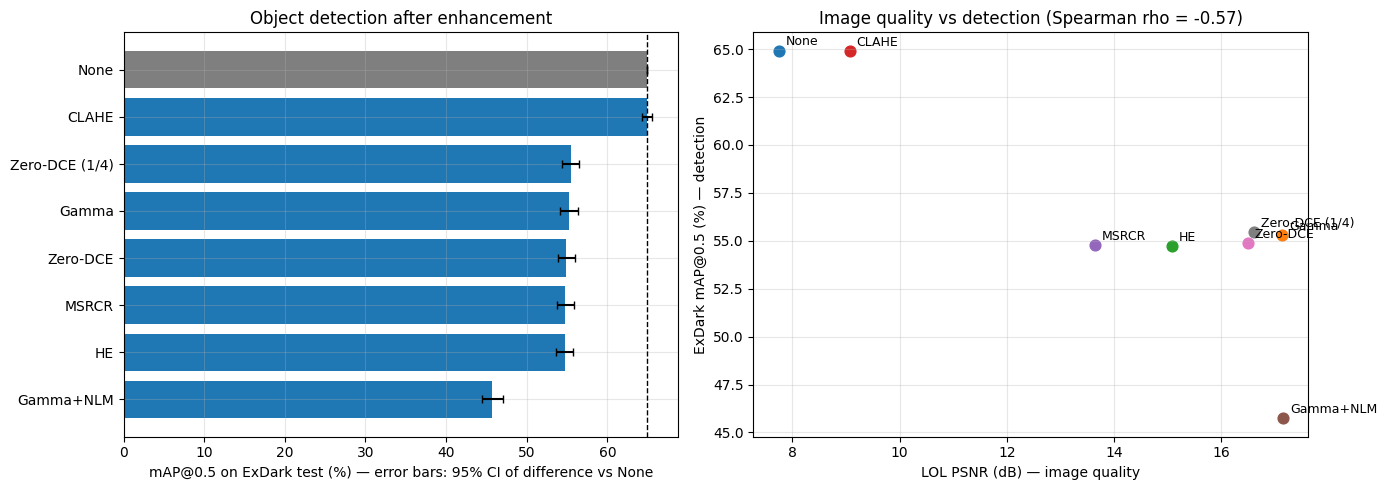

Saved detection_results.json + figures/detection_results.png


In [6]:
# Cell 7 — Detection evaluation: mAP, bootstrap CIs vs None, per class, per lighting, quality-vs-detection
from torchmetrics.detection import MeanAveragePrecision
from scipy.stats import spearmanr

state = pickle.load(open(PRED_PATH, 'rb'))
METHODS_L, gts, meta = state['methods'], state['gt'], state['meta']
N, K = len(gts), len(CLASSES)
print(f'Images: {N} | methods: {METHODS_L}')

# ---------- 1. Official COCO metrics (torchmetrics) ----------
def tm_map(m):
    metric = MeanAveragePrecision(box_format='xyxy', iou_type='bbox')
    P = [dict(boxes=torch.tensor(p['boxes']), scores=torch.tensor(p['scores']), labels=torch.tensor(p['labels']))
         for p in state['preds'][m]]
    T = [dict(boxes=torch.tensor(g['boxes']), labels=torch.tensor(g['labels'])) for g in gts]
    metric.update(P, T)
    r = metric.compute()
    return float(r['map']), float(r['map_50'])

# ---------- 2. Fast AP@0.5 (per-detection TP flags computed once, then bootstrap) ----------
def iou_1n(b, B):
    x1 = np.maximum(b[0], B[:, 0]); y1 = np.maximum(b[1], B[:, 1])
    x2 = np.minimum(b[2], B[:, 2]); y2 = np.minimum(b[3], B[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    return inter / ((b[2] - b[0]) * (b[3] - b[1]) + (B[:, 2] - B[:, 0]) * (B[:, 3] - B[:, 1]) - inter + 1e-9)

def match(p, g, thr=0.5):
    tp = np.zeros(len(p['scores']), bool)
    used = np.zeros(len(g['labels']), bool)
    for j in np.argsort(-p['scores']):
        cand = np.where((g['labels'] == p['labels'][j]) & ~used)[0]
        if len(cand) == 0:
            continue
        ious = iou_1n(p['boxes'][j], g['boxes'][cand])
        k = ious.argmax()
        if ious[k] >= thr:
            tp[j] = True; used[cand[k]] = True
    return tp

TP = {m: [match(state['preds'][m][i], gts[i]) for i in range(N)] for m in METHODS_L}
NGT = np.array([[int((g['labels'] == c).sum()) for c in range(K)] for g in gts])   # (N, K)

def ap50(m, idx):
    """COCO-style 101-point AP@0.5 per class over image indices idx (with repeats for bootstrap)."""
    aps = []
    for c in range(K):
        n_gt = NGT[idx, c].sum()
        if n_gt == 0:
            continue
        sc, tp = [], []
        for i in idx:
            p = state['preds'][m][i]
            sel = p['labels'] == c
            sc.append(p['scores'][sel]); tp.append(TP[m][i][sel])
        sc, tp = np.concatenate(sc), np.concatenate(tp)
        if len(sc) == 0:
            aps.append(0.0); continue
        o = np.argsort(-sc, kind='stable')
        tpc, fpc = np.cumsum(tp[o]), np.cumsum(~tp[o])
        rec, prec = tpc / n_gt, tpc / (tpc + fpc)
        prec = np.maximum.accumulate(prec[::-1])[::-1]
        rs = np.linspace(0, 1, 101)
        pos = np.searchsorted(rec, rs, side='left')
        aps.append(np.mean([prec[q] if q < len(prec) else 0.0 for q in pos]))
    return float(np.mean(aps)), aps

all_idx = np.arange(N)
rows = {}
for m in METHODS_L:
    mp, mp50 = tm_map(m)
    rows[m] = dict(map=mp, map50_tm=mp50, map50=ap50(m, all_idx)[0],
                   ms=float(np.median(state['ms'][m])))
print('\nCheck — custom AP50 vs torchmetrics AP50:',
      {m: f"{rows[m]['map50']:.4f}/{rows[m]['map50_tm']:.4f}" for m in METHODS_L[:3]})

# ---------- 3. Bootstrap CI of mAP@0.5 difference vs None (paired resampling) ----------
rng = np.random.default_rng(42)
B = 1000
boot_idx = [rng.integers(0, N, N) for _ in range(B)]
base_boot = np.array([ap50('None', bi)[0] for bi in boot_idx])
for m in METHODS_L:
    if m == 'None':
        rows[m].update(d50=0.0, ci=[0.0, 0.0]); continue
    d = np.array([ap50(m, bi)[0] for bi in boot_idx]) - base_boot
    rows[m].update(d50=rows[m]['map50'] - rows['None']['map50'], ci=np.percentile(d, [2.5, 97.5]).tolist())
    print(f'bootstrap done: {m}')

print(f"\n{'method':<16}{'mAP':>8}{'mAP@0.5':>9}{'Δ vs None':>11}{'95% CI':>20}{'ms/img':>9}")
for m in METHODS_L:
    r = rows[m]
    print(f"{m:<16}{r['map']:>8.4f}{r['map50']:>9.4f}{r['d50']*100:>+10.2f}  "
          f"[{r['ci'][0]*100:+6.2f}, {r['ci'][1]*100:+6.2f}]{r['ms']:>9.1f}")

# ---------- 4. Per class and per lighting (AP@0.5) ----------
per_class = {m: ap50(m, all_idx)[1] for m in METHODS_L}
print(f"\nAP@0.5 per class\n{'class':<11}" + ''.join(f'{m[:9]:>10}' for m in METHODS_L))
for c in range(K):
    print(f'{CLASSES[c]:<11}' + ''.join(f'{per_class[m][c]:>10.3f}' for m in METHODS_L))

lights = [l for l, _ in Counter(x['light'] for x in meta).most_common()]
per_light = {}
print(f"\nmAP@0.5 per lighting type\n{'light (n)':<16}" + ''.join(f'{m[:9]:>10}' for m in METHODS_L))
for l in lights:
    idx = np.array([i for i, x in enumerate(meta) if x['light'] == l])
    per_light[l] = {m: ap50(m, idx)[0] for m in METHODS_L}
    print(f'{l + f" ({len(idx)})":<16}' + ''.join(f'{per_light[l][m]:>10.3f}' for m in METHODS_L))

# ---------- 5. Does image quality predict detection? ----------
q_psnr = [np.mean(lol_res[m]['psnr']) for m in METHODS_L]
q_ssim = [np.mean(lol_res[m]['ssim']) for m in METHODS_L]
det50 = [rows[m]['map50'] for m in METHODS_L]
rp, pp = spearmanr(q_psnr, det50)
rs_, ps_ = spearmanr(q_ssim, det50)
print(f'\nSpearman (8 methods): LOL PSNR vs ExDark mAP@0.5 rho = {rp:+.2f} (p={pp:.2f}) | '
      f'SSIM vs mAP@0.5 rho = {rs_:+.2f} (p={ps_:.2f})')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
order = sorted(METHODS_L, key=lambda m: rows[m]['map50'])
vals = [rows[m]['map50'] * 100 for m in order]
err = np.array([[(rows[m]['d50'] - rows[m]['ci'][0]) * 100, (rows[m]['ci'][1] - rows[m]['d50']) * 100] for m in order]).T
ax[0].barh(order, vals, xerr=err, color=['tab:gray' if m == 'None' else 'tab:blue' for m in order], capsize=3)
ax[0].axvline(rows['None']['map50'] * 100, color='k', ls='--', lw=1)
ax[0].set(xlabel='mAP@0.5 on ExDark test (%) — error bars: 95% CI of difference vs None',
          title='Object detection after enhancement')
for m, x, y in zip(METHODS_L, q_psnr, det50):
    ax[1].scatter(x, y * 100, s=60); ax[1].annotate(m, (x, y * 100), xytext=(5, 4), textcoords='offset points', fontsize=9)
ax[1].set(xlabel='LOL PSNR (dB) — image quality', ylabel='ExDark mAP@0.5 (%) — detection',
          title=f'Image quality vs detection (Spearman rho = {rp:+.2f})')
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/figures/detection_results.png', dpi=120)
plt.show()

with open(f'{PROJECT_DIR}/results/detection_results.json', 'w') as f:
    json.dump(dict(detector='torchvision fasterrcnn_resnet50_fpn_v2 (COCO), score>=0.05, max side 800',
                   n_images=N, overall=rows, per_class={m: dict(zip(CLASSES, v)) for m, v in per_class.items()},
                   per_light=per_light, spearman=dict(psnr=[rp, pp], ssim=[rs_, ps_])), f, indent=1)
print('Saved detection_results.json + figures/detection_results.png')

In [7]:
# Cell 8 — Why does enhancement hurt? Recall, false positives, precision and confidence (score >= 0.5)
n_gt = int(NGT.sum())
rows8 = {}
for m in METHODS_L:
    tp_hi = fp_hi = tp_all = 0
    tp_scores = []
    for i in range(N):
        p, t = state['preds'][m][i], TP[m][i]
        hi = p['scores'] >= 0.5
        tp_hi += int((t & hi).sum()); fp_hi += int((~t & hi).sum())
        tp_all += int(t.sum())
        tp_scores.extend(p['scores'][t].tolist())
    rows8[m] = dict(recall_05=tp_hi / n_gt, max_recall=tp_all / n_gt, fp_per_img=fp_hi / N,
                    precision_05=tp_hi / max(tp_hi + fp_hi, 1), mean_tp_score=float(np.mean(tp_scores)))

print(f"Ground-truth boxes: {n_gt}\n")
print(f"{'method':<16}{'recall@0.5':>11}{'max recall':>12}{'FP/img':>9}{'precision':>11}{'TP score':>10}")
for m in METHODS_L:
    r = rows8[m]
    print(f"{m:<16}{r['recall_05']:>11.3f}{r['max_recall']:>12.3f}{r['fp_per_img']:>9.2f}"
          f"{r['precision_05']:>11.3f}{r['mean_tp_score']:>10.3f}")

det = json.load(open(f'{PROJECT_DIR}/results/detection_results.json'))
det['failure_analysis'] = rows8
with open(f'{PROJECT_DIR}/results/detection_results.json', 'w') as f:
    json.dump(det, f, indent=1)
print('\nSaved failure analysis into detection_results.json')

Ground-truth boxes: 7117

method           recall@0.5  max recall   FP/img  precision  TP score
None                  0.723       0.835     1.81      0.525     0.839
Gamma                 0.613       0.746     1.63      0.511     0.798
HE                    0.611       0.733     1.81      0.483     0.810
CLAHE                 0.726       0.839     1.94      0.509     0.841
MSRCR                 0.623       0.755     2.07      0.456     0.803
Gamma+NLM             0.496       0.646     1.30      0.515     0.748
Zero-DCE              0.610       0.748     1.81      0.484     0.794
Zero-DCE (1/4)        0.622       0.754     1.85      0.482     0.799

Saved failure analysis into detection_results.json


In [ ]:
# Cell 9 — README figures (LOL images + charts only) + export package
REPO = '/content/repo_export'
for sub in ['figures', 'results', 'models']:
    os.makedirs(f'{REPO}/{sub}', exist_ok=True)
det = json.load(open(f'{PROJECT_DIR}/results/detection_results.json'))
M_ALL = ['None', 'Gamma', 'HE', 'CLAHE', 'MSRCR', 'Gamma+NLM', 'Zero-DCE', 'Zero-DCE (1/4)']

# ---------- 1. LOL examples (official test images) ----------
picks = [i for i, (s, *_) in enumerate(lol) if s == 'eval15'][:3]
cols = M_ALL[1:]
fig, axes = plt.subplots(len(picks), len(cols) + 2, figsize=(2.6 * (len(cols) + 2), 2.1 * len(picks)))
for r, i in enumerate(picks):
    _, n, low, high = lol[i]
    panels = [('Low (input)', low, psnr(high, low, data_range=255))]
    for m in cols:
        out = METHODS[m](low)
        panels.append((m, out, psnr(high, out, data_range=255)))
    panels.append(('Reference', high, None))
    for c, (title, img, p) in enumerate(panels):
        a = axes[r, c]
        a.imshow(img); a.set_xticks([]); a.set_yticks([])
        if r == 0:
            a.set_title(title, fontsize=10)
        if p is not None:
            a.set_xlabel(f'{p:.1f} dB', fontsize=9)
plt.tight_layout()
plt.savefig(f'{REPO}/figures/lol_examples.png', dpi=100); plt.show()

# ---------- 2. LOL quality ----------
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ps = [np.mean(lol_res[m]['psnr']) for m in M_ALL]
ss = [np.mean(lol_res[m]['ssim']) for m in M_ALL]
ax[0].barh(M_ALL, ps, color='tab:blue'); ax[0].set(xlabel='PSNR (dB)', title='LOL image quality — PSNR (500 pairs)')
ax[1].barh(M_ALL, ss, color='tab:green'); ax[1].set(xlabel='SSIM', title='LOL image quality — SSIM (500 pairs)')
for a, v in zip(ax, [ps, ss]):
    a.invert_yaxis(); a.grid(alpha=0.3, axis='x')
    for y, x in enumerate(v):
        a.text(x, y, f' {x:.2f}', va='center', fontsize=9)
plt.tight_layout(); plt.savefig(f'{REPO}/figures/lol_quality.png', dpi=110); plt.show()

# ---------- 3. Detection per lighting type (heatmap of numbers) ----------
lights = list(det['per_light'])
mat = np.array([[det['per_light'][l][m] for m in M_ALL] for l in lights]) * 100
n_light = Counter(x['light'] for x in state['meta'])
fig, ax = plt.subplots(figsize=(12, 5.5))
im = ax.imshow(mat - mat[:, [0]], cmap='RdBu', vmin=-25, vmax=25)
ax.set_xticks(range(len(M_ALL)), M_ALL, rotation=30, ha='right')
ax.set_yticks(range(len(lights)), [f'{l} ({n_light[l]})' for l in lights])
for y in range(len(lights)):
    for x in range(len(M_ALL)):
        ax.text(x, y, f'{mat[y, x]:.1f}', ha='center', va='center', fontsize=8)
ax.set_title('ExDark mAP@0.5 (%) per lighting type — colour = change vs None (blue better, red worse)')
plt.colorbar(im, ax=ax, label='Δ mAP@0.5 vs None (pts)')
plt.tight_layout(); plt.savefig(f'{REPO}/figures/detection_per_lighting.png', dpi=110); plt.show()

# ---------- 4. Failure analysis ----------
fa = det['failure_analysis']
x = np.arange(len(M_ALL)); w = 0.27
fig, ax = plt.subplots(figsize=(13, 4.5))
for k, (key, lab) in enumerate([('recall_05', 'recall (score ≥ 0.5)'), ('max_recall', 'recall (any score)'),
                                ('precision_05', 'precision (score ≥ 0.5)')]):
    ax.bar(x + (k - 1) * w, [fa[m][key] for m in M_ALL], w, label=lab)
ax.set_xticks(x, M_ALL, rotation=20); ax.set_ylim(0.3, 0.9); ax.legend(); ax.grid(alpha=0.3, axis='y')
ax.set_title('Why enhancement hurts detection: objects are missed (recall drops), precision stays similar')
plt.tight_layout(); plt.savefig(f'{REPO}/figures/failure_analysis.png', dpi=110); plt.show()

# ---------- 5. Zero-DCE training curve ----------
hist = json.load(open(f'{PROJECT_DIR}/results/zero_dce_history.json'))
plt.figure(figsize=(6, 3.5)); plt.plot(range(1, len(hist) + 1), hist)
plt.xlabel('epoch'); plt.ylabel('zero-reference loss'); plt.title('Zero-DCE training (ExDark train, 3,000 images)')
plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig(f'{REPO}/figures/zero_dce_training.png', dpi=110); plt.show()

# ---------- 6. Collect files ----------
shutil.copyfile(f'{PROJECT_DIR}/figures/detection_results.png', f'{REPO}/figures/detection_results.png')
for fn in ['lol_all_methods.json', 'detection_results.json', 'zero_dce_history.json']:
    shutil.copyfile(f'{PROJECT_DIR}/results/{fn}', f'{REPO}/results/{fn}')
for fn in ['zero_dce_final.pt', 'zero_dce.onnx']:
    shutil.copyfile(f'{PROJECT_DIR}/checkpoints/{fn}', f'{REPO}/models/{fn}')

shutil.make_archive(f'{PROJECT_DIR}/repo_export', 'zip', REPO)
for root, _, files in os.walk(REPO):
    for fn in sorted(files):
        p = os.path.join(root, fn)
        print(f'  {os.path.relpath(p, REPO):<40} {os.path.getsize(p)/1e6:6.2f} MB')
print(f'\nSaved {PROJECT_DIR}/repo_export.zip')